# E-cell simulation – publication plot
Simulate cell voltage for charge and discharge, compare against experiment.  
Plot style: single black model curve, filled circles (charge) and open circles (discharge).  
**Workflow:** edit the *Parameters* cell -> run all -> read the plot.

In [ ]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path
from solve_dae.integrate import solve_dae

ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "scripts" / "Experimental"))

from simulate_HFR import build_cell, build_atol, soc_cutoff_event  # noqa: E402
from rfbmodel1D.parameters.params import cathodeparams, anodeparams, membraneparams, cellparams

## -- Parameters --

In [2]:
# -- test selection -------------------------------------------------------------
TEST_NO = 5

# -- fit results ----------------------------------------------------------------
# Path relative to scripts/Experimental/fit_results/, or None to use defaults
FIT_DIR = ROOT / "results" / "test fitting" / f"test {TEST_NO}"
HFR_FIT    = sorted(FIT_DIR.glob(f"fit_v2_test{TEST_NO}_*.json"))[-1].name
E_CELL_FIT = sorted(FIT_DIR.glob(f"fit_e_cell_test{TEST_NO}_*.json"))[-1].name

# -- solver settings ------------------------------------------------------------
TF     = 1800
RTOL   = 1e-5
STRIDE = 1

In [3]:


# -- apply HFR membrane params --------------------------------------------------
if HFR_FIT is not None:
    with open(FIT_DIR / HFR_FIT) as f:
        _hfr = json.load(f)
    _p = _hfr["params"]
    _s = _hfr["settings"]
    membraneparams.k_sorp_vw   = _p["k_vw_sorp"]
    membraneparams.k_desorp_vw = _p["S_desorp"] * _p["k_vw_sorp"]
    membraneparams.k_sorp_lw   = _p["k_lw_sorp"]
    membraneparams.k_desorp_lw = _p["S_desorp"] * _p["k_lw_sorp"]
    membraneparams.k_ca_lw     = _p["k_ca"]
    membraneparams.sf_D        = _s["sf_D"]
    cellparams.vanadium_uptake = False
    print(f"HFR membrane params loaded from: {HFR_FIT}")

# -- apply E-cell kinetic params ------------------------------------------------
if E_CELL_FIT is not None:
    with open(FIT_DIR / E_CELL_FIT) as f:
        _ec = json.load(f)
    k_ca  = _ec["params"]["k_ca"]
    j0_an = _ec["params"]["j0_an"]
    print(f"E-cell params loaded from: {E_CELL_FIT}")

cathodeparams.reaction_rate_constant = k_ca
anodeparams.j_0                      = j0_an
print(f"k_ca = {k_ca:.4e} m/s   j0_an = {j0_an:.4e} A/m²")

# -- load experimental data -----------------------------------------------------
csv  = ROOT / "data" / "experimental" / "E_cell.csv"
data = pd.read_csv(csv)
data = data[data["test_no"] == TEST_NO]

soc = data["SOC"].iloc[0]
T   = data["T(°C)"].iloc[0]
Q_v = data["Q_v (ml/min)"].iloc[0]

j_charge    = data[data["mode"] == "charge"]["j_appl (A/m2)"].values[::STRIDE]
j_discharge = data[data["mode"] == "discharge"]["j_appl (A/m2)"].values[::STRIDE]
E_exp_ch    = data[data["mode"] == "charge"]["value (V)"].values[::STRIDE]
E_exp_dis   = data[data["mode"] == "discharge"]["value (V)"].values[::STRIDE]

print(f"Test {TEST_NO}: SOC={soc}, T={T}°C, Q_v={Q_v} ml/min")
print(f"Charge: {len(j_charge)} pts   Discharge: {len(j_discharge)} pts")

HFR membrane params loaded from: fit_v2_test5_20260613_185943.json
E-cell params loaded from: fit_e_cell_test5_20260614_000424.json
k_ca = 1.0961e-06 m/s   j0_an = 1.3634e+03 A/m²
Test 5: SOC=0.1, T=32°C, Q_v=45 ml/min
Charge: 8 pts   Discharge: 7 pts


## -- Run simulations --

In [4]:
def run_sim(j_appl: float) -> float:
    """Run a single steady-state simulation and return E_cell [V]."""
    cell, y0, yp0 = build_cell(soc, j_appl, T, Q_v)
    atol          = build_atol(cell)
    jac_sparsity  = cell.compute_jac_sparsity(y0, yp0)
    t0 = time.time()
    sol = solve_dae(
        cell.dae_residual_full_cell,
        (0.0, TF), y0, yp0,
        method="BDF", atol=atol, rtol=RTOL,
        events=soc_cutoff_event, jac_sparsity=jac_sparsity,
    )
    if sol.t[-1] < 0.99 * TF:
        print(f"  Warning: simulation terminated at t={sol.t[-1]:.2f} s (event triggered?)")
    y_final        = sol.y[:, -1]
    Nc             = cell.mesh.cathode_mesh.n_x
    n_vars_cathode = cell.layout.n_vars_cathode
    n_vars_tank    = cell.layout.n_vars_tank
    offset_cathode = n_vars_tank
    Phi_el_final   = y_final[offset_cathode:offset_cathode + Nc * n_vars_cathode].reshape(Nc, n_vars_cathode)[:, 4]
    dx             = cell.mesh.cathode_mesh.dx[0] * cell.cathode.thickness
    sigma_el       = cell.cathode.eff_conductivity
    E_cell         = float(Phi_el_final[0] + j_appl * (dx / 2) / sigma_el)
    print(f"  j={j_appl:+8.0f} A/m²  E_cell={E_cell:.4f} V  ({time.time()-t0:.1f}s)")
    return E_cell


def interior_points(arr, n=1):
    """Return n equally-spaced interior points between each consecutive pair."""
    pts = []
    for a, b in zip(arr[:-1], arr[1:]):
        pts.extend(np.linspace(a, b, n + 2)[1:-1])
    return np.array(pts)


# -- Charge --------------------------------------------------------------------
print("=== Charge ===")
_res_ch  = [run_sim(float(j)) for j in j_charge]
E_sim_ch = _res_ch

j_ch_fill = interior_points(j_charge, n=3)
print("=== Charge fill points ===")
E_sim_ch_fill = [run_sim(float(j)) for j in j_ch_fill]

j_model_ch = np.concatenate([j_charge, j_ch_fill])
E_model_ch = np.concatenate([E_sim_ch, E_sim_ch_fill])
sort_idx   = np.argsort(j_model_ch)
j_model_ch = j_model_ch[sort_idx]
E_model_ch = E_model_ch[sort_idx]

# -- Discharge -----------------------------------------------------------------
print("=== Discharge ===")
_res_dis  = [run_sim(-float(j)) for j in j_discharge]
E_sim_dis = _res_dis

j_dis_fill = interior_points(j_discharge, n=3)
print("=== Discharge fill points ===")
E_sim_dis_fill = [run_sim(-float(j)) for j in j_dis_fill]

j_model_dis = np.concatenate([j_discharge, j_dis_fill])
E_model_dis = np.concatenate([E_sim_dis, E_sim_dis_fill])
sort_idx    = np.argsort(j_model_dis)
j_model_dis = j_model_dis[sort_idx]
E_model_dis = E_model_dis[sort_idx]

# -- MSE / APE (original experimental points only) -----------------------------
E_exp_all = np.concatenate([E_exp_ch, E_exp_dis])
E_sim_all = np.array(E_sim_ch + E_sim_dis)
mse = float(np.mean((E_sim_all - E_exp_all) ** 2))
ape = float(np.mean(np.abs((E_sim_all - E_exp_all) / E_exp_all)) * 100)
print(f"\nMSE = {mse:.6f}  RMSE = {mse**0.5:.4f} V  APE = {ape:.2f}%")

=== Charge ===
  j=      +0 A/m²  E_cell=1.0772 V  (1.7s)
  j=   +1477 A/m²  E_cell=1.1845 V  (9.7s)
  j=   +1985 A/m²  E_cell=1.2181 V  (10.6s)
  j=   +2494 A/m²  E_cell=1.2499 V  (11.9s)
  j=   +2993 A/m²  E_cell=1.2796 V  (15.2s)
  j=   +3491 A/m²  E_cell=1.3079 V  (15.4s)
Call 20000: t=57.653340, max|res|=1.547699e-03
  j=   +4000 A/m²  E_cell=1.3385 V  (35.1s)
Call 20000: t=36.794287, max|res|=6.065424e-04
  j=   +4509 A/m²  E_cell=1.3715 V  (52.6s)
=== Charge fill points ===
  j=    +369 A/m²  E_cell=1.1064 V  (2.4s)
  j=    +738 A/m²  E_cell=1.1332 V  (9.1s)
  j=   +1108 A/m²  E_cell=1.1593 V  (9.2s)
  j=   +1604 A/m²  E_cell=1.1930 V  (13.2s)
  j=   +1731 A/m²  E_cell=1.2015 V  (13.2s)
  j=   +1858 A/m²  E_cell=1.2098 V  (14.1s)
  j=   +2112 A/m²  E_cell=1.2262 V  (13.1s)
  j=   +2240 A/m²  E_cell=1.2342 V  (13.6s)
  j=   +2367 A/m²  E_cell=1.2421 V  (13.8s)
  j=   +2619 A/m²  E_cell=1.2575 V  (14.8s)
  j=   +2743 A/m²  E_cell=1.2649 V  (15.4s)
  j=   +2868 A/m²  E_cell=1.2723 

## -- Results --

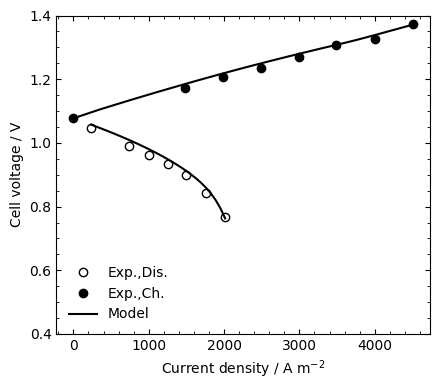

In [6]:
fig, ax = plt.subplots(figsize=(4.5, 4))

# Experimental: filled circles (charge), open circles (discharge)
ax.plot(j_discharge, E_exp_dis, 'o', ms=6, mfc='none', mec='k', mew=1.0,
        label='Exp.,Dis.')
ax.plot(j_charge,    E_exp_ch,  'o', ms=6, mfc='k',    mec='k', mew=1.0,
        label='Exp.,Ch.')

# Model: denser black line (original + midpoints, sorted)
ax.plot(j_model_ch,  E_model_ch,  '-', color='k', lw=1.5, label='Model')
ax.plot(j_model_dis, E_model_dis, '-', color='k', lw=1.5)

ax.set_ylim(0.4, 1.4)
ax.set_xlabel('Current density / A m$^{-2}$')
ax.set_ylabel('Cell voltage / V')
ax.legend(frameon=False)
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.tick_params(which='both', direction='in', top=True, right=True)

plt.tight_layout()
out_path = ROOT / f"figures/E_cell_test{TEST_NO}.pdf"
out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_path, bbox_inches='tight')


plt.show()